# 06 — Baseline: Fault Tree Analysis (FTA)

Last stage of the ISRO-inspired baseline: **UMAP → K-Means → LAD → FTA**.

**Inputs (all produced by earlier notebooks):**
- `train_FD004_with_clusters.csv` — notebook 04 output (all 249 engines, with K-Means `cluster`)
- `val_FD004_with_lad_predictions.csv` — notebook 05 output (50 held-out engines)
- `lad_rules.txt` — notebook 05 output (the learned IF-THEN rules)

**What this notebook does:** turns the LAD rules into a fault tree with *minimal cut sets*, maps the sensors in them to gas-path measurement locations, and checks how well the tree works as an engine-level alarm.

**What it does not do:** it cannot name a failed component. FD004 has no per-engine fault labels, so nothing here can be checked against a ground-truth fault. Every claim below is about *sensor patterns*, not confirmed faults.

## 1. Teaching first: what a fault tree is

A fault tree is a diagram that explains **how an undesired event can happen** by breaking it into simpler events joined by logic gates.

| Term | Meaning | In this project |
|---|---|---|
| **Top event** | The undesired outcome at the root | "Engine is in degraded cluster X" |
| **Basic event** | A lowest-level event, not broken down further | One sensor condition, e.g. `s_12 > 1.05` |
| **AND gate** | Output happens only if **all** inputs happen | One LAD rule = AND of its conditions |
| **OR gate** | Output happens if **any** input happens | All rules of one cluster = OR of rules |
| **Cut set** | A set of basic events that together cause the top event | One LAD rule |
| **Minimal cut set** | A cut set where removing any event breaks it, i.e. not already covered by a smaller or more general one | A rule not contained in another rule of the same cluster |

So the tree has a fixed shape: `TOP EVENT = OR( AND(events…), AND(events…), … )`, and the list of minimal cut sets is the most compact readable summary of it.

**How classical FTA differs from what we do here.** Classical FTA is built *top-down by engineers* from known failure mechanisms, and is usually quantified: each basic event gets a failure probability, and the top-event probability is computed through the gates assuming the basic events are independent. We build the tree *bottom-up from data*, so:

1. The cut sets describe sensor patterns that **co-occur** with a cluster. They are not proven **causes**.
2. The sensors are strongly correlated (see notebook 02), so the independence assumption fails. **We do not compute probabilities.** Anything computed that way would look precise and mean nothing.
3. A sensor's *location* in the engine tells you where it measures, not where the fault is. A compressor-outlet temperature can move because of degradation upstream or downstream.

What FTA does give us here is **interpretability**: a short list of human-readable sensor conditions per cluster, which a black-box model such as an LSTM does not offer. That is the angle your project is built around. Your ISRO documents describe FTA only qualitatively (no algorithm was specified), so this notebook gives one concrete, reproducible definition.

## 2. Config and loading

In [1]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = '.'    # folder holding the three input files; change if yours are elsewhere
CLUSTERS_CSV = f'{DATA_DIR}/train_FD004_with_clusters.csv'
VAL_CSV      = f'{DATA_DIR}/val_FD004_with_lad_predictions.csv'
RULES_TXT    = f'{DATA_DIR}/lad_rules.txt'
OUT_DIR      = './fta_output'
os.makedirs(OUT_DIR, exist_ok=True)

MIN_PRECISION = 0.85   # keep rules that reached the purity target LAD was trained with (notebook 05 picked 0.85)
PERSIST_K     = 5      # alarm = tree event holds for K consecutive cycles (fixed in advance, not tuned)
RUL_CEILING   = 125    # same ceiling used when RUL was clipped in notebook 02
END_WINDOW    = 15     # 'end of life' = last 15 cycles

df = pd.read_csv(CLUSTERS_CSV).sort_values(['unit_number', 'time_cycles']).reset_index(drop=True)
val = pd.read_csv(VAL_CSV).sort_values(['unit_number', 'time_cycles']).reset_index(drop=True)
rule_lines = [l for l in open(RULES_TXT).read().strip().split('\n') if l.strip()]

# unclipped cycles-to-failure (RUL in the file is clipped at 125)
for d in (df, val):
    d['life'] = d.groupby('unit_number')['time_cycles'].transform('max')
    d['ttf'] = d['life'] - d['time_cycles']

print(f'all engines: {df.unit_number.nunique()} | validation engines: {val.unit_number.nunique()} | rules in file: {len(rule_lines)}')

all engines: 249 | validation engines: 50 | rules in file: 40


## 3. Sensor meaning (from the C-MAPSS paper, Table 2)

Only the 14 sensors that survived preprocessing appear. The *measurement location* grouping is our own convenience for reading the tree; it is **not** a diagnosis.

In [2]:
SENSOR_INFO = {   # sensor: (C-MAPSS symbol, what it measures, measurement-location group)
    's_2':  ('T24',     'LPC outlet temperature',          'LPC'),
    's_3':  ('T30',     'HPC outlet temperature',          'HPC'),
    's_4':  ('T50',     'LPT outlet temperature',          'Turbine and cooling'),
    's_7':  ('P30',     'HPC outlet pressure',             'HPC'),
    's_8':  ('Nf',      'Physical fan speed',              'Fan and bypass'),
    's_9':  ('Nc',      'Physical core speed',             'Core speed'),
    's_11': ('Ps30',    'HPC outlet static pressure',      'HPC'),
    's_12': ('phi',     'Fuel flow / Ps30',                'Combustor and fuel'),
    's_13': ('NRf',     'Corrected fan speed',             'Fan and bypass'),
    's_14': ('NRc',     'Corrected core speed',            'Core speed'),
    's_15': ('BPR',     'Bypass ratio',                    'Fan and bypass'),
    's_17': ('htBleed', 'Bleed enthalpy',                  'Bleed air'),
    's_20': ('W31',     'HPT coolant bleed',               'Turbine and cooling'),
    's_21': ('W32',     'LPT coolant bleed',               'Turbine and cooling'),
}
pd.DataFrame(SENSOR_INFO, index=['symbol', 'measures', 'location group']).T

,symbol,measures,location group
s_2,T24,LPC outlet temperature,LPC
s_3,T30,HPC outlet temperature,HPC
s_4,T50,LPT outlet temperature,Turbine and cooling
s_7,P30,HPC outlet pressure,HPC
s_8,Nf,Physical fan speed,Fan and bypass
s_9,Nc,Physical core speed,Core speed
s_11,Ps30,HPC outlet static pressure,HPC
s_12,phi,Fuel flow / Ps30,Combustor and fuel
s_13,NRf,Corrected fan speed,Fan and bypass
s_14,NRc,Corrected core speed,Core speed


## 4. Before building the tree: are the clusters degradation *stages* or something else?

The tree structure depends on this. If the clusters were stages (healthy → moderate → advanced), every engine would pass through them in order and we would build one tree per stage. Earlier in this project the clusters were described as stages. **That was a reading of the RUL boxplots, not a tested claim.** Here it is tested directly on all 249 engines.

Two checks: (a) which cluster does each engine end its life in, and (b) which clusters does each engine pass through along the way.

In [3]:
df['life_frac'] = df['time_cycles'] / df['life']
role = df.groupby('cluster').agg(rows=('RUL', 'size'),
                                mean_RUL=('RUL', 'mean'),
                                median_life_frac=('life_frac', 'median'),
                                share_first30=('life_frac', lambda s: (s <= 0.30).mean())).round(3)
healthy = int(role['mean_RUL'].idxmax())
degraded = [int(c) for c in role.index if c != healthy]
print('median_life_frac = where in an engine\'s life the cluster\'s rows typically fall (0 = start, 1 = failure)')
print('share_first30    = share of the cluster\'s rows that lie in the first 30% of engine life\n')
print(role)

end = (df[df.ttf < END_WINDOW].groupby('unit_number')['cluster']
         .agg(lambda s: s.value_counts().idxmax()).rename('end_cluster'))
df = df.join(end, on='unit_number')
visits = df.groupby(['unit_number', 'cluster']).size().unstack(fill_value=0)

print(f'\nhealthy cluster (highest mean RUL): {healthy}')
print('engines by the cluster they END life in:', end.value_counts().sort_index().to_dict())
for c in degraded:
    print(f'  engines with >=5 cycles in cluster {c}: {(visits[c] >= 5).sum()}')
print('  engines with >=5 cycles in BOTH degraded clusters:', int(((visits[degraded[0]] >= 5) & (visits[degraded[1]] >= 5)).sum()))
life_by_end = df.groupby('unit_number')['life'].first().groupby(end).median()
print('median engine lifespan (cycles) by end cluster:', life_by_end.to_dict())

median_life_frac = where in an engine's life the cluster's rows typically fall (0 = start, 1 = failure)
share_first30    = share of the cluster's rows that lie in the first 30% of engine life

          rows  mean_RUL  median_life_frac  share_first30
cluster                                                  
0        25234    79.567             0.601          0.211
1         9316    54.121             0.844          0.024
2        26699   119.228             0.316          0.476

healthy cluster (highest mean RUL): 2
engines by the cluster they END life in: {0: 148, 1: 101}
  engines with >=5 cycles in cluster 0: 149
  engines with >=5 cycles in cluster 1: 101
  engines with >=5 cycles in BOTH degraded clusters: 1
median engine lifespan (cycles) by end cluster: {0: 200.5, 1: 288.0}


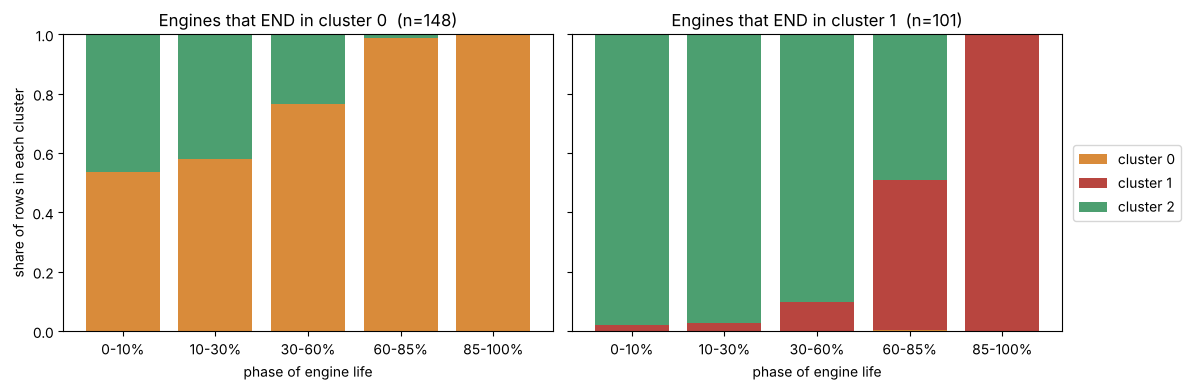

cluster                 0     1     2
end_cluster phase                    
0           0-10%    0.54  0.00  0.46
            10-30%   0.58  0.00  0.42
            30-60%   0.77  0.00  0.23
            60-85%   0.99  0.00  0.01
            85-100%  1.00  0.00  0.00
1           0-10%    0.00  0.02  0.98
            10-30%   0.00  0.03  0.97
            30-60%   0.00  0.10  0.90
            60-85%   0.00  0.51  0.49
            85-100%  0.00  1.00  0.00

In [4]:
df['phase'] = pd.cut(df['time_cycles'] / df['life'], [0, .1, .3, .6, .85, 1.0],
                     labels=['0-10%', '10-30%', '30-60%', '60-85%', '85-100%'])
occ = (df.groupby(['end_cluster', 'phase'], observed=True)['cluster']
         .value_counts(normalize=True).unstack(fill_value=0))
COLORS = {healthy: '#4c9f70', degraded[0]: '#d98b3a', degraded[1]: '#b8453f'}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, ec in zip(axes, sorted(end.unique())):
    sub = occ.loc[ec]
    bottom = np.zeros(len(sub))
    for c in sorted(sub.columns):
        ax.bar(sub.index.astype(str), sub[c].values, bottom=bottom, color=COLORS[c], label=f'cluster {c}')
        bottom += sub[c].values
    n_eng = int((end == ec).sum())
    ax.set_title(f'Engines that END in cluster {ec}  (n={n_eng})')
    ax.set_xlabel('phase of engine life')
axes[0].set_ylabel('share of rows in each cluster')
axes[1].legend(loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fta_cluster_paths.png', dpi=130)
plt.show()
occ.round(2)

**What the check shows (read the numbers above):** the two non-healthy clusters are **not** successive stages. Each engine ends life in one of them, and essentially no engine visits both. They are two separate end-of-life regions, matching the two arms in the UMAP plot.

The two regions also behave differently along the way:
- The cluster that engines enter *late* and stay in (very few of its rows in the first 30% of life) is a clean degraded state: those engines start in the healthy cluster and move into it near the end.
- The other cluster is **mixed**: its engines sit in it right from the start of life, interleaved with the healthy cluster, so being in it does not by itself mean "degrading".

**Consequence for the tree:** one tree per non-healthy cluster (two top events, not a stage ladder), and the mixed cluster is a weaker alarm. This is a limitation of the unsupervised baseline and is worth carrying into the comparison with Alternatives 1 and 2.

What this does **not** show is *why* the engines split into two regions. FD004 is documented as having two fault modes, but the files carry no label saying which engine has which, so we cannot say the two regions are those fault modes.

## 5. Parse the LAD rules, prune them, and find minimal cut sets

**Parsing.** Each rule line looks like `IF s_15 > 1.0065 AND s_2 > 0.1002 THEN cluster=0 (precision=1.00, coverage=54)`. Each rule's conditions become one interval per sensor, so `s_9 <= -0.13 AND s_9 > -0.73` becomes the single interval `(-0.73, -0.13]`.

**Pruning.** The sequential-covering learner finishes each class with leftover fragments that never reached the purity target. They have precision as low as 0.13 and often repeat a near-vacuous condition (`s_2 > -2.0899`, true for 99% of rows). Those are artefacts of the search, not patterns, so rules below `MIN_PRECISION` are dropped. (Precision here is measured on the 1,200-row LAD training sample; the validation check comes later.)

**Minimal cut sets.** A rule is redundant if its region lies entirely inside another rule's region for the same cluster. Removing it leaves the OR of the cluster's rules unchanged.

In [5]:
RULE_RE = re.compile(r'IF (.*) THEN cluster=(\d+) \(precision=([\d.]+), coverage=(\d+)\)')
COND_RE = re.compile(r'(s_\d+) (<=|>) (-?[\d.]+)')

def to_box(conds):
    # per-sensor interval (lo, hi]:  lo < x <= hi
    box = {}
    for s, op, t in conds:
        lo, hi = box.get(s, (-np.inf, np.inf))
        box[s] = (lo, min(hi, t)) if op == '<=' else (max(lo, t), hi)
    return box

def fires(box, data):
    m = np.ones(len(data), dtype=bool)
    for s, (lo, hi) in box.items():
        m &= (data[s].values > lo) & (data[s].values <= hi)
    return m

def inside(a, b):
    # True if region(a) is a subset of region(b)
    return all(a.get(s, (-np.inf, np.inf))[0] >= lo and a.get(s, (-np.inf, np.inf))[1] <= hi
               for s, (lo, hi) in b.items())

rules = []
for i, line in enumerate(rule_lines):
    m = RULE_RE.match(line)
    conds = [(s, op, float(t)) for s, op, t in COND_RE.findall(m.group(1))]
    rules.append(dict(rule_id=i, cluster=int(m.group(2)), precision=float(m.group(3)),
                      coverage=int(m.group(4)), box=to_box(conds)))

kept = [r for r in rules if r['precision'] >= MIN_PRECISION]
print(f'{len(rules)} rules parsed -> {len(kept)} kept at precision >= {MIN_PRECISION}')

cutsets = []
for r in kept:
    redundant = any(o['rule_id'] != r['rule_id'] and o['cluster'] == r['cluster']
                    and inside(r['box'], o['box'])
                    and not (inside(o['box'], r['box']) and o['rule_id'] > r['rule_id'])
                    for o in kept)
    if not redundant:
        cutsets.append(r)
cutsets = sorted(cutsets, key=lambda r: (-r['precision'], -r['coverage']))
for k, r in enumerate(cutsets, 1):
    r['cs_id'] = f'CS-{k:02d}'
print(f'{len(cutsets)} minimal cut sets  ->', pd.Series([r['cluster'] for r in cutsets]).value_counts().sort_index().to_dict(), '(by cluster)')

40 rules parsed -> 27 kept at precision >= 0.85
22 minimal cut sets  -> {0: 8, 1: 4, 2: 10} (by cluster)


## 6. Held-out check of every cut set

The precision in the rules file comes from the training sample. Here each cut set is re-measured on the 50 held-out engines: when it fires, how often is the row really in its cluster (`val_precision`), and how much of that cluster's rows does it catch (`val_recall`)?

In [6]:
def describe(box):
    parts = []
    for s, (lo, hi) in box.items():
        sym = SENSOR_INFO[s][0]
        if np.isinf(lo):   parts.append(f'{s} ({sym}) <= {hi:.3f}')
        elif np.isinf(hi): parts.append(f'{s} ({sym}) > {lo:.3f}')
        else:              parts.append(f'{lo:.3f} < {s} ({sym}) <= {hi:.3f}')
    return ' AND '.join(parts)

rows = []
for r in cutsets:
    f = fires(r['box'], val)
    own = (val['cluster'].values == r['cluster'])
    rows.append(dict(cut_set=r['cs_id'], cluster=r['cluster'], n_events=len(r['box']),
                     train_precision=r['precision'],
                     val_fires=int(f.sum()),
                     val_precision=round((f & own).sum() / f.sum(), 3) if f.sum() else np.nan,
                     val_recall=round((f & own).sum() / own.sum(), 3),
                     condition=describe(r['box'])))
cs_table = pd.DataFrame(rows)
cs_table.to_csv(f'{OUT_DIR}/cut_sets.csv', index=False)
pd.set_option('display.max_colwidth', 90, 'display.width', 200)
cs_table

,cut_set,cluster,n_events,train_precision,val_fires,val_precision,val_recall,condition
0,CS-01,0,2,1.00,3306,0.996,0.553,s_15 (BPR) > 0.542 AND s_2 (T24) > 0.100
1,CS-02,0,2,1.00,3296,0.999,0.553,s_15 (BPR) > 0.340 AND s_4 (T50) > 0.355
2,CS-03,1,1,1.00,1066,0.979,0.644,s_15 (BPR) <= -1.286
3,CS-04,2,2,1.00,1488,0.995,0.338,s_11 (Ps30) <= -0.675 AND s_2 (T24) <= -0.713
4,CS-05,2,2,1.00,855,0.980,0.191,s_17 (htBleed) <= -1.300 AND s_8 (Nf) <= 0.144
5,CS-06,0,2,1.00,3160,0.996,0.529,s_15 (BPR) > 0.034 AND s_11 (Ps30) > 0.487
6,CS-07,2,1,0.95,443,0.948,0.096,s_2 (T24) <= -1.602
7,CS-08,2,2,0.95,2055,0.993,0.465,s_11 (Ps30) <= -0.694 AND s_4 (T50) <= -0.568
8,CS-09,0,2,0.94,2798,0.992,0.466,s_15 (BPR) > -0.031 AND s_17 (htBleed) > 0.595
9,CS-10,2,1,0.94,466,0.968,0.103,s_3 (T30) <= -1.614


## 7. The fault tree

Printed as text first, then drawn. Only the two **non-healthy** clusters get a tree, because a fault tree describes an undesired event. The healthy cluster's rules are listed separately as the *normal-state signature*.

In [7]:
def cluster_name(c):
    if c == healthy: return 'Healthy region'
    return ('Late-life degraded state' if role.loc[c, 'share_first30'] < 0.10
            else 'Mixed region (early- and late-life rows)')

lines = []
for c in degraded:
    cs = [r for r in cutsets if r['cluster'] == c]
    lines.append(f'TOP EVENT: "{cluster_name(c)}"  [cluster {c}]')
    lines.append('  OR of %d minimal cut sets' % len(cs))
    for k, r in enumerate(cs):
        last = (k == len(cs) - 1)
        tr = '└─' if last else '├─'
        pad = '   ' if last else '│  '
        row = cs_table[cs_table.cut_set == r['cs_id']].iloc[0]
        lines.append(f'  {tr} AND  {r["cs_id"]}   (val precision {row.val_precision}, catches {row.val_recall:.0%} of the cluster)')
        for j, (s, (lo, hi)) in enumerate(r['box'].items()):
            ev = describe({s: (lo, hi)})
            lines.append(f'  {pad}   {"└─" if j == len(r["box"]) - 1 else "├─"} {ev}')
    lines.append('')
tree_text = '\n'.join(lines)
open(f'{OUT_DIR}/fault_tree.txt', 'w').write(tree_text)
print(tree_text)

TOP EVENT: "Mixed region (early- and late-life rows)"  [cluster 0]
  OR of 8 minimal cut sets
  ├─ AND  CS-01   (val precision 0.996, catches 55% of the cluster)
  │     ├─ s_15 (BPR) > 0.542
  │     └─ s_2 (T24) > 0.100
  ├─ AND  CS-02   (val precision 0.999, catches 55% of the cluster)
  │     ├─ s_15 (BPR) > 0.340
  │     └─ s_4 (T50) > 0.355
  ├─ AND  CS-06   (val precision 0.996, catches 53% of the cluster)
  │     ├─ s_15 (BPR) > 0.034
  │     └─ s_11 (Ps30) > 0.487
  ├─ AND  CS-09   (val precision 0.992, catches 47% of the cluster)
  │     ├─ s_15 (BPR) > -0.031
  │     └─ s_17 (htBleed) > 0.595
  ├─ AND  CS-13   (val precision 0.995, catches 56% of the cluster)
  │     ├─ s_15 (BPR) > 0.328
  │     └─ s_2 (T24) > 0.373
  ├─ AND  CS-14   (val precision 0.98, catches 47% of the cluster)
  │     └─ s_15 (BPR) > 0.791
  ├─ AND  CS-18   (val precision 0.985, catches 52% of the cluster)
  │     ├─ s_15 (BPR) > -0.021
  │     ├─ s_3 (T30) > 0.382
  │     └─ s_7 (P30) <= 0.133
  └─ AND

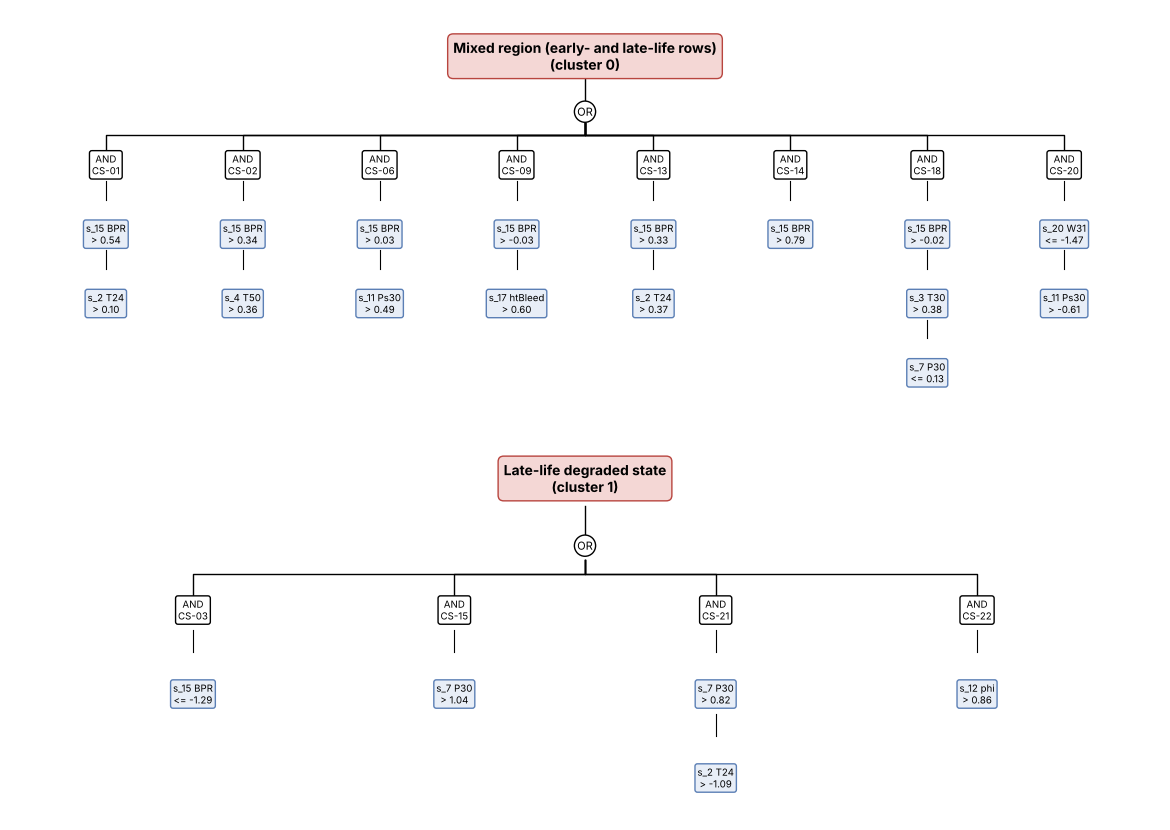

In [8]:
def ev_label(s, lo, hi):
    sym = SENSOR_INFO[s][0]
    if np.isinf(lo):   cond = f'<= {hi:.2f}'
    elif np.isinf(hi): cond = f'> {lo:.2f}'
    else:              cond = f'({lo:.2f}, {hi:.2f}]'
    return f'{s} {sym}\n{cond}'

def draw_tree(ax, c):
    cs = [r for r in cutsets if r['cluster'] == c]
    n = len(cs); max_ev = max(len(r['box']) for r in cs)
    mid = (n - 1) / 2
    ax.set_xlim(-0.7, n - 0.3); ax.set_ylim(-0.62 - 0.3 * max_ev, 0.2); ax.axis('off')
    ax.text(mid, 0.0, f'{cluster_name(c)}\n(cluster {c})', ha='center', va='center', fontsize=10, weight='bold',
            bbox=dict(boxstyle='round,pad=0.4', fc='#f4d7d5', ec='#b8453f'))
    ax.plot([mid, mid], [-0.1, -0.2], 'k', lw=1)
    ax.text(mid, -0.24, 'OR', ha='center', va='center', fontsize=8, bbox=dict(boxstyle='circle,pad=0.25', fc='white', ec='k'))
    for i, r in enumerate(cs):
        ax.plot([mid, mid, i, i], [-0.29, -0.34, -0.34, -0.42], 'k', lw=1)
        ax.text(i, -0.47, f'AND\n{r["cs_id"]}', ha='center', va='center', fontsize=7,
                bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='k'))
        y = -0.47
        for s, (lo, hi) in r['box'].items():
            ax.plot([i, i], [y - 0.07, y - 0.15], 'k', lw=0.8)
            y -= 0.3
            ax.text(i, y, ev_label(s, lo, hi), ha='center', va='center', fontsize=7,
                    bbox=dict(boxstyle='round,pad=0.25', fc='#e8eef7', ec='#5b7fb5'))

n_max = max(sum(r['cluster'] == c for r in cutsets) for c in degraded)
fig, axes = plt.subplots(len(degraded), 1, figsize=(max(9, 1.35 * n_max + 1), 4.2 * len(degraded)))
for ax, c in zip(np.atleast_1d(axes), degraded):
    draw_tree(ax, c)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fault_tree.png', dpi=140)
plt.show()

In [9]:
print('NORMAL-STATE SIGNATURE (healthy cluster %d), top cut sets by val precision:\n' % healthy)
print(cs_table[cs_table.cluster == healthy].sort_values('val_precision', ascending=False)
      [['cut_set', 'val_fires', 'val_precision', 'val_recall', 'condition']].to_string(index=False))

NORMAL-STATE SIGNATURE (healthy cluster 2), top cut sets by val precision:

cut_set  val_fires  val_precision  val_recall                                           condition
  CS-04       1488          0.995       0.338       s_11 (Ps30) <= -0.675 AND s_2 (T24) <= -0.713
  CS-08       2055          0.993       0.465       s_11 (Ps30) <= -0.694 AND s_4 (T50) <= -0.568
  CS-19       1853          0.992       0.420                               s_11 (Ps30) <= -0.944
  CS-11       1192          0.985       0.268         s_3 (T30) <= -0.849 AND s_2 (T24) <= -0.579
  CS-16       1174          0.984       0.264                                 s_4 (T50) <= -1.151
  CS-05        855          0.980       0.191      s_17 (htBleed) <= -1.300 AND s_8 (Nf) <= 0.144
  CS-17       1937          0.976       0.431       s_3 (T30) <= -0.735 AND s_11 (Ps30) <= -0.358
  CS-10        466          0.968       0.103                                 s_3 (T30) <= -1.614
  CS-12       1037          0.963       0.

## 8. Which measurement locations show up in each tree?

For each tree and location group: the share of that cluster's held-out rows where at least one cut set *containing a sensor from that group* fires. Several groups can fire on the same row, so the shares do not add to 100%.

Reminder: a sensor's location says where it measures, not where the fault is.

In [10]:
groups = sorted({v[2] for v in SENSOR_INFO.values()})
out = {}
for c in degraded:
    own = (val['cluster'].values == c)
    col = {}
    for g in groups:
        hit = np.zeros(len(val), dtype=bool)
        for r in cutsets:
            if r['cluster'] == c and any(SENSOR_INFO[s][2] == g for s in r['box']):
                hit |= fires(r['box'], val)
        col[g] = round((hit & own).sum() / own.sum(), 3)
    out[f'{cluster_name(c)} (cluster {c})'] = col
loc_table = pd.DataFrame(out)
loc_table.to_csv(f'{OUT_DIR}/location_groups.csv')
loc_table

,Mixed region (early- and late-life rows) (cluster 0),Late-life degraded state (cluster 1)
Bleed air,0.466,0.000
Combustor and fuel,0.000,0.867
Core speed,0.000,0.000
Fan and bypass,0.867,0.644
HPC,0.694,0.871
LPC,0.627,0.838
Turbine and cooling,0.572,0.000


## 9. How well does the tree work as an engine-level diagnosis?

The tree predicts a cluster per row: the first matching cut set (highest precision first) decides; if nothing fires the tree stays **silent** rather than guessing.

Three row-level checks on the 50 held-out engines: how often the tree speaks at all, how often it is right when it speaks, and how often cut sets from different clusters contradict each other.

In [11]:
pred = np.full(len(val), -1)
for r in cutsets:                       # cutsets are already sorted by precision
    m = fires(r['box'], val) & (pred == -1)
    pred[m] = r['cluster']
val['tree_stage'] = pred

covered = pred != -1
print(f'tree speaks on {covered.mean():.1%} of rows; silent on {(~covered).mean():.1%}')
print(f'agreement with the K-Means label when it speaks: {(pred[covered] == val.loc[covered, "cluster"].values).mean():.1%}')

fire_any = {c: np.zeros(len(val), bool) for c in sorted(val.cluster.unique())}
for r in cutsets:
    fire_any[r['cluster']] |= fires(r['box'], val)
n_clusters_firing = sum(v.astype(int) for v in fire_any.values())
print(f'rows where cut sets from 2+ different clusters fire at once: {(n_clusters_firing > 1).mean():.1%}\n')

ct = pd.crosstab(val['cluster'].rename('true K-Means cluster'),
                 pd.Series(np.where(pred == -1, 'silent', pred.astype(str)), name='tree says'))
print(ct)

tree speaks on 86.4% of rows; silent on 13.6%
agreement with the K-Means label when it speaks: 97.3%
rows where cut sets from 2+ different clusters fire at once: 2.7%

tree says                0     1     2  silent
true K-Means cluster                          
0                     5154     1    72     725
1                        0  1494    39      87
2                       82    80  3403     818


### Engine-level alarm and early-detection timing

A row-level cluster label is not yet an alarm. An alarm is defined here as: **the tree event holds for `PERSIST_K` consecutive cycles**. `PERSIST_K` is fixed in advance at 5, and 3 and 10 are shown only to see how sensitive the result is, not to pick the best.

Each alarm is judged against the true cycles-to-failure at the moment it fires:
- **valid** — raised with 125 or fewer cycles left (the same ceiling the RUL labels use for "meaningfully degrading");
- **early** — raised with more than 125 cycles left, which is the closest available stand-in for a false alarm, because every FD004 engine runs to failure and there are no healthy engines to false-alarm on;
- **missed** — never raised.

The "reference" rows apply the same alarm rule to the K-Means label itself, to show what the cluster labels alone would give. It is not an upper bound for the tree: the tree stays silent on some rows, which breaks runs and can delay (or avoid) an early alarm.

In [12]:
def first_alarm(g, stage_col, stages, k):
    flag = g[stage_col].isin(stages).astype(int).values
    run = 0
    for i, f in enumerate(flag):
        run = run + 1 if f else 0
        if run >= k:
            return dict(cycle=g['time_cycles'].values[i], ttf=g['ttf'].values[i],
                        life_used=g['time_cycles'].values[i] / g['life'].values[0])
    return None

late = [c for c in degraded if role.loc[c, 'share_first30'] < 0.10]
defs = {'any non-healthy event': degraded}
if late:
    defs = {f'late-life event (cluster {late[0]})': late, **defs}

res = []
for name, stages in defs.items():
    for source, col in (('tree', 'tree_stage'), ('reference: K-Means label', 'cluster')):
        for k in (3, PERSIST_K, 10):
            al = [first_alarm(g, col, stages, k) for _, g in val.groupby('unit_number')]
            got = [a for a in al if a]
            valid = [a for a in got if a['ttf'] <= RUL_CEILING]
            res.append(dict(event=name, source=source, K=k, engines=len(al), alarmed=len(got),
                            valid=len(valid), early=len(got) - len(valid), missed=len(al) - len(got),
                            median_lead_cycles_valid=float(np.median([a['ttf'] for a in valid])) if valid else np.nan,
                            median_life_used_valid=round(float(np.median([a['life_used'] for a in valid])), 2) if valid else np.nan))
alarm_table = pd.DataFrame(res)
alarm_table.to_csv(f'{OUT_DIR}/engine_alarm_table.csv', index=False)
alarm_table

,event,source,K,engines,alarmed,valid,early,missed,median_lead_cycles_valid,median_life_used_valid
0,late-life event (cluster 1),tree,3,50,17,14,3,33,64.0,0.78
1,late-life event (cluster 1),tree,5,50,17,15,2,33,54.0,0.80
2,late-life event (cluster 1),tree,10,50,17,15,2,33,48.0,0.82
3,late-life event (cluster 1),reference: K-Means label,3,50,17,14,3,33,65.5,0.77
4,late-life event (cluster 1),reference: K-Means label,5,50,17,15,2,33,68.0,0.78
5,late-life event (cluster 1),reference: K-Means label,10,50,17,15,2,33,57.0,0.81
6,any non-healthy event,tree,3,50,50,21,29,0,66.0,0.75
7,any non-healthy event,tree,5,50,50,30,20,0,62.5,0.75
8,any non-healthy event,tree,10,50,50,35,15,0,58.0,0.78
9,any non-healthy event,reference: K-Means label,3,50,50,21,29,0,80.0,0.74


## 10. Save and summarise

In [13]:
a5 = alarm_table[alarm_table.K == PERSIST_K]
print('FILES WRITTEN to', OUT_DIR, ':', sorted(os.listdir(OUT_DIR)))
print()
print('SUMMARY (all numbers from the cells above)')
print(f'- {len(rules)} LAD rules -> {len(kept)} after pruning -> {len(cutsets)} minimal cut sets')
print(f'- clusters: healthy={healthy}; non-healthy={degraded}; engines end in', end.value_counts().sort_index().to_dict())
print(f'- tree speaks on {covered.mean():.0%} of held-out rows, {(pred[covered] == val.loc[covered, "cluster"].values).mean():.0%} agreement with K-Means when it does')
print(a5[['event', 'source', 'alarmed', 'valid', 'early', 'missed', 'median_lead_cycles_valid']].to_string(index=False))

FILES WRITTEN to ./fta_output : ['cut_sets.csv', 'engine_alarm_table.csv', 'fault_tree.png', 'fault_tree.txt', 'fta_cluster_paths.png', 'location_groups.csv']

SUMMARY (all numbers from the cells above)
- 40 LAD rules -> 27 after pruning -> 22 minimal cut sets
- clusters: healthy=2; non-healthy=[0, 1]; engines end in {0: 148, 1: 101}
- tree speaks on 86% of held-out rows, 97% agreement with K-Means when it does
                      event                   source  alarmed  valid  early  missed  median_lead_cycles_valid
late-life event (cluster 1)                     tree       17     15      2      33                      54.0
late-life event (cluster 1) reference: K-Means label       17     15      2      33                      68.0
      any non-healthy event                     tree       50     30     20       0                      62.5
      any non-healthy event reference: K-Means label       50     23     27       0                      74.0


## What to carry into the write-up

**Established here, by running it on the data:**
1. The two non-healthy clusters are two separate end-of-life regions, not stages of one ladder. This corrects the earlier "degradation stages" description.
2. The pruned LAD rules compress to a small set of minimal cut sets, each re-checked on held-out engines, so the tree is genuinely readable.
3. The clean late-life cluster gives usable advance warning, but only for the engines that enter it. The mixed cluster cannot serve as a degradation alarm on its own.

**Scope of 'held-out' (important for the paper):** only the LAD rules were learned without the 50 validation engines. UMAP (notebook 03) and K-Means (notebook 04) were fit on all 249 engines, so the cluster labels the tree is scored against were not held out. Read the held-out numbers as 'the rules generalise to unseen engines', not as an end-to-end held-out result.

**Not established, do not claim:**
- Any named failed component. Sensor location is not fault location.
- That the two regions are the two documented FD004 fault modes. The files carry no per-engine fault label to test that.
- Any probability of failure from the tree.
- That LAD or the tree detects faults independently of K-Means: both only reproduce the cluster labels.

**For the comparison stage:** the baseline's alarm coverage (how many engines it ever flags) is a limitation to test against Alternative 1 and against the LSTM's RUL output, which does not depend on this cluster geometry. Validation is only 50 engines, so differences of a few engines are within noise.